In [2]:
%run ../Preprocessing/Preprocessing.ipynb

--------------PREPROCESSING:  ORIGINAL --------------


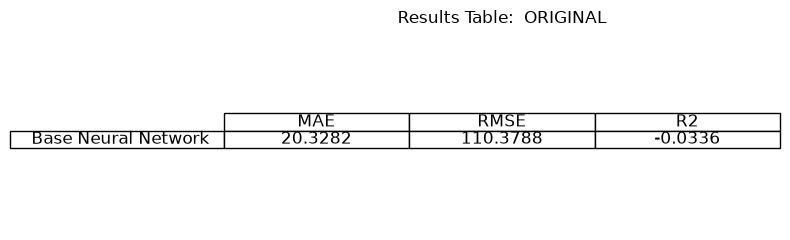

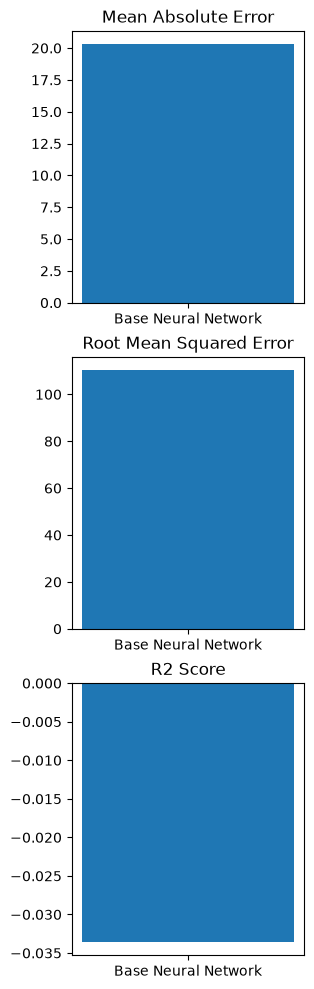

--------------PREPROCESSING:  ALL --------------


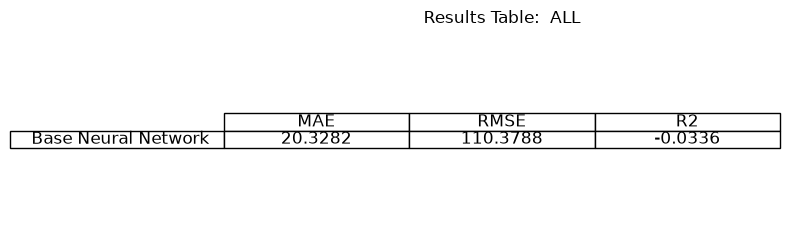

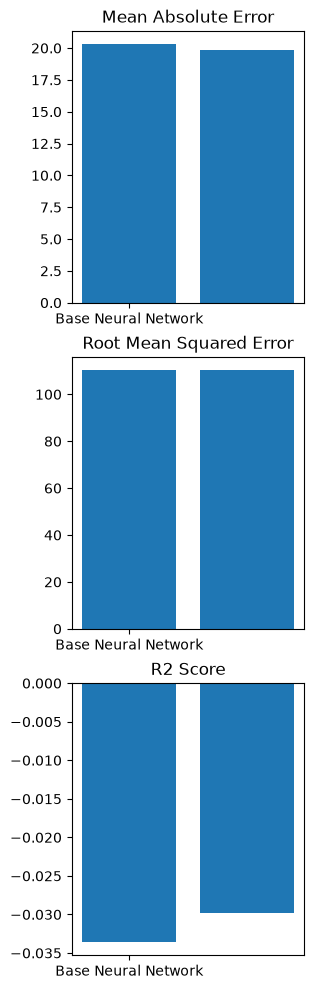

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------


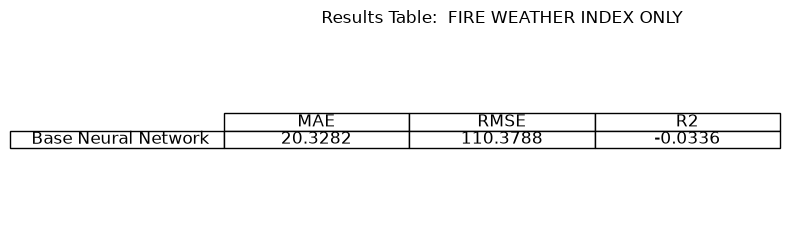

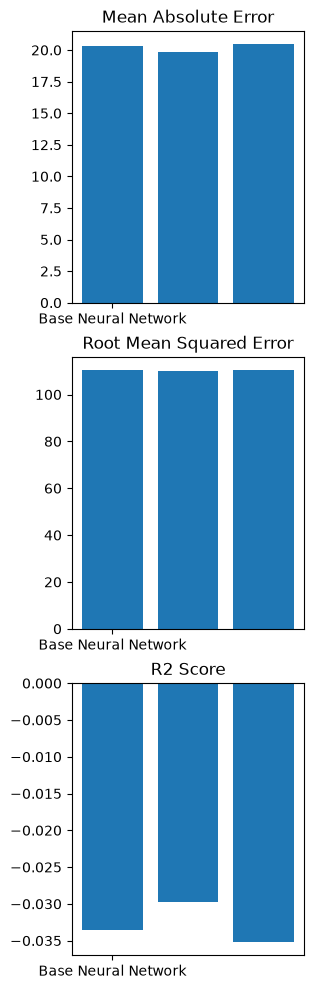

--------------PREPROCESSING:  VERY PRUNED (TEST) --------------


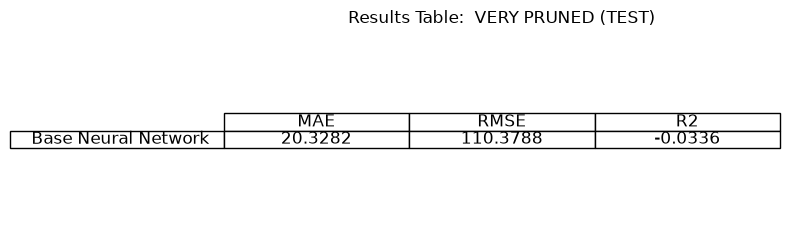

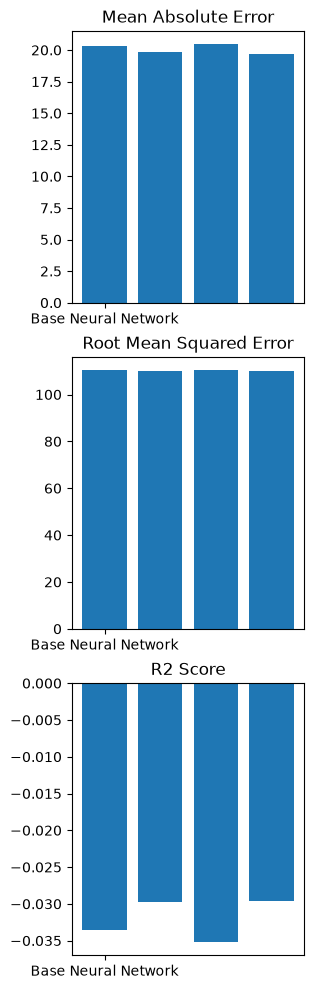

In [7]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

X = df[categorical_columns + numerical_columns]
y = df["area"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=RANDOM_STATE)

resultsMAE =[]
resultsRMSE = []
resultsR2 = []

models = {
    "Base Neural Network" : MLPRegressor(random_state=RANDOM_STATE, max_iter=2000, tol=0.1)
}


for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    for name, model in models.items():
        
        model = make_pipeline(preprocessing, model)
        model.fit(X_train, np.log1p(y_train))
        pred = np.expm1(model.predict(X_test))
        mae = mean_absolute_error(y_test, pred)
        rmse = root_mean_squared_error(y_test, pred)
        r2 = r2_score(y_test, pred)
        residuals = (y_test - pred)
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)

    #Plot Results
    model_names = list(models.keys())
    plt.figure(figsize={8, 2 + len(model_names)*0.5})
    plt.axis("off")
    columns = ["MAE", "RMSE", "R2"]
    text = []
    for i in range(len(model_names)):
        text.append([f"{resultsMAE[i]:.4f}",f"{resultsRMSE[i]:.4f}",f"{resultsR2[i]:.4f}"])
    
    table = plt.table(
        cellText = text,
        rowLabels = model_names,
        colLabels = columns,
        loc="center",
        cellLoc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    plt.title(f"Results Table:  {title}")
    plt.tight_layout()
    plt.show
    
    plt.figure(figsize={12,len(model_names) * 3}) ##Figure is dynamically sized to allow for more models to be added as needed


    plt.subplot(311, title="Mean Absolute Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(model_names)),model_names)
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(model_names)),model_names)
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(model_names)),model_names)

    plt.show()
